# This method is also applicable to numeric columns. `Winsorization` is same as capping. When we do capping under percentile method, it is called `winsorization`.

To understand how this works, let's first understand what is percentile?
* Supose that a student got 85 marks in english and it i 95 percentile, it means marks of 95% of students are below him.
* Supose that maximum marks in any subject is 95, then this is 100 percentile because maximum anyone can get is 95.

# How will we perform Trimming and capping in this case?

* We'll decide thresshold here. Say threshold is 99 percentile, it means every mark which is above 99 percentile and below 1 percentile is an outlier. <br>
We can then remove these rows or can cap them.
* In capping we'll take the nearest value. For example, suppose we decided the threshold as 95 percentile and mark at 95 percentile is 70, then in this case we'll cap all those values which are above 95 percentile with the immediate smaller value of 70

# Generally everyone takes threshold as `0.99` and `0.1`

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('00 weights_heights.csv')

In [3]:
df.head()

# Here we'll work with height column.

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [4]:
df['Height'].describe()

count    10000.000000
mean        66.367560
std          3.847528
min         54.263133
25%         63.505620
50%         66.318070
75%         69.174262
max         78.998742
Name: Height, dtype: float64

<AxesSubplot: ylabel='Density'>

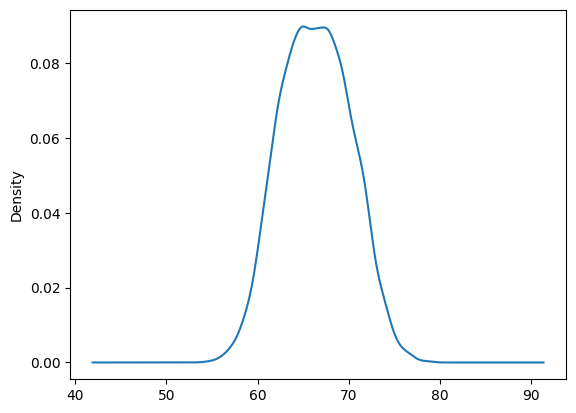

In [5]:
# Let see the distribution of the data points

df['Height'].plot(kind = 'kde')

# We can see it's almost normally distributed.

C:\Users\jugal\AppData\Local\Temp\ipykernel_16948\3945773010.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Height'])


<AxesSubplot: xlabel='Height', ylabel='Density'>

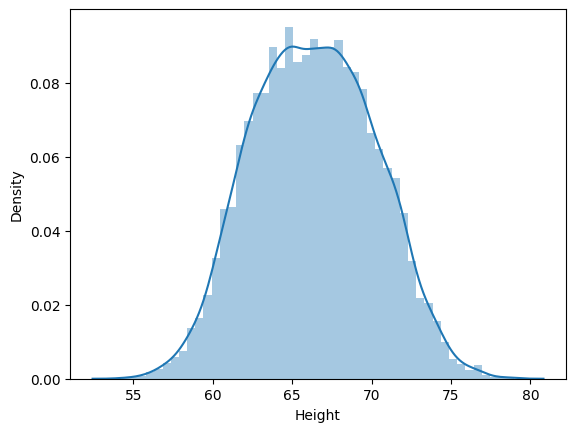

In [6]:
sns.distplot(df['Height'])

<AxesSubplot: xlabel='Height'>

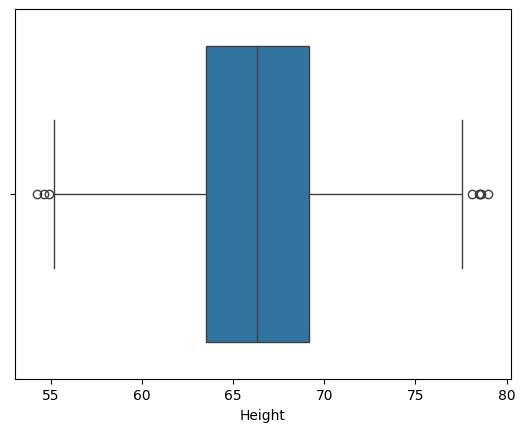

In [7]:
sns.boxplot(df.Height, orient = 'h')

# Decide threshold, i.e lower and upper limit.

In [8]:
lower_limit = df['Height'].quantile(0.01)

In [9]:
upper_limit = df.Height.quantile(0.99)

In [10]:
print(f'Lower limit: {lower_limit}')
print(f'Upper limit: {upper_limit}')

Lower limit: 58.13441158671655
Upper limit: 74.7857900583366


In [11]:
# Let's find the outliers.

outliers = df[
(df['Height'] <= lower_limit) |
(df['Height'] >= upper_limit)
]

In [12]:
outliers

,Gender,Height,Weight
23,Male,75.205974,228.761781
190,Male,76.709835,235.035419
197,Male,75.944460,231.924749
202,Male,75.140821,224.124271
215,Male,74.795375,232.635403
...,...,...,...
9761,Female,56.975279,90.341784
9825,Female,55.979198,85.417534
9895,Female,57.740192,93.652957
9904,Female,57.028857,101.202551


# Trimming

In [13]:
trimed_df = df[(df['Height'] > lower_limit) & (df['Height'] < upper_limit)]

In [14]:
trimed_df

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801
...,...,...,...
9995,Female,66.172652,136.777454
9996,Female,67.067155,170.867906
9997,Female,63.867992,128.475319
9998,Female,69.034243,163.852461


In [15]:
trimed_df.Height.describe()

count    9800.000000
mean       66.364366
std         3.645075
min        58.134496
25%        63.577162
50%        66.318070
75%        69.119896
max        74.785714
Name: Height, dtype: float64

In [16]:
df.Height.describe()

count    10000.000000
mean        66.367560
std          3.847528
min         54.263133
25%         63.505620
50%         66.318070
75%         69.174262
max         78.998742
Name: Height, dtype: float64

# Comparison after `trimming`.

C:\Users\jugal\AppData\Local\Temp\ipykernel_16948\3492653308.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Height'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_16948\3492653308.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(trimed_df['Height'])


Text(0.5, 1.0, 'Height after trimming')

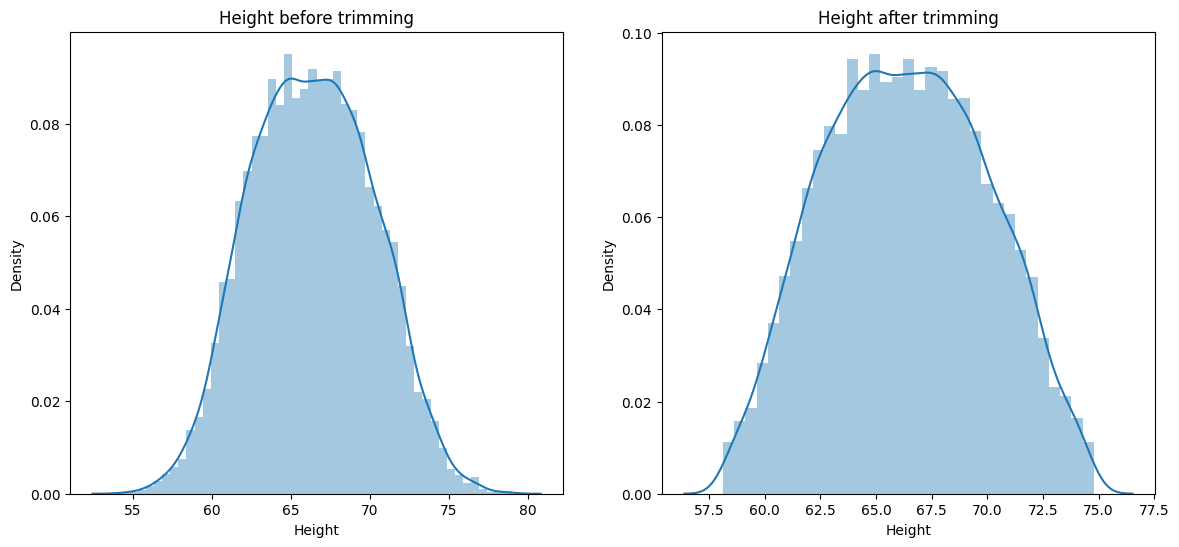

In [17]:
plt.figure(figsize = (14, 6))

plt.subplot(121)
sns.distplot(df['Height'])
plt.title("Height before trimming")

plt.subplot(122)
sns.distplot(trimed_df['Height'])
plt.title('Height after trimming')

# We can see that distribution is also same before and after trimming.

Text(0.5, 1.0, 'Height after trimming')

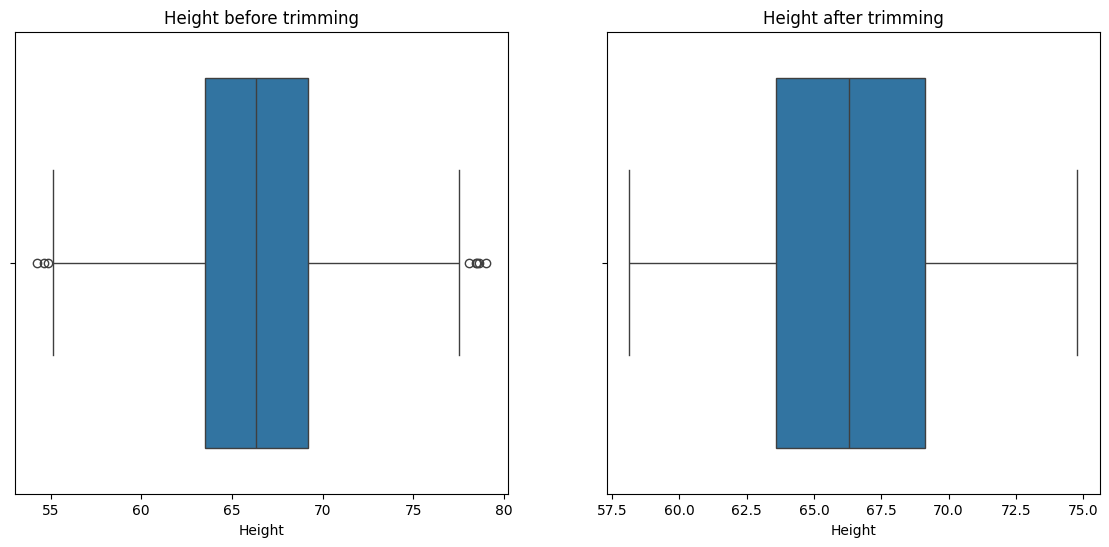

In [29]:
plt.figure(figsize = (14, 6))

plt.subplot(121)
sns.boxplot(df['Height'], orient = 'h')
plt.title("Height before trimming")

plt.subplot(122)
sns.boxplot(trimed_df['Height'], orient = 'h')
plt.title('Height after trimming')

# We can see there're no outliers now.

# Capping(Winsorization)

In [21]:
df2 = df.copy()

In [22]:
df2['Capped_height'] = np.where(df2['Height'] > upper_limit, upper_limit,
                    np.where(df2['Height'] < lower_limit, lower_limit, df2['Height']))

In [24]:
df2.sample(10)

,Gender,Height,Weight,Capped_height
6993,Female,61.528212,117.654738,61.528212
4439,Male,68.949858,196.035690,68.949858
1789,Male,72.185992,215.868614,72.185992
1594,Male,70.474161,200.361282,70.474161
655,Male,65.224692,160.836074,65.224692
900,Male,74.216431,238.569451,74.216431
6714,Female,58.037418,100.496831,58.134412
7423,Female,62.817780,122.412693,62.817780
601,Male,67.115564,168.202167,67.115564
4132,Male,70.447792,199.383453,70.447792


# Comparing after capping

C:\Users\jugal\AppData\Local\Temp\ipykernel_16948\2066045160.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Height'])
C:\Users\jugal\AppData\Local\Temp\ipykernel_16948\2066045160.py:10: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df2['Capped_height'])


Text(0.5, 1.0, 'After capping')

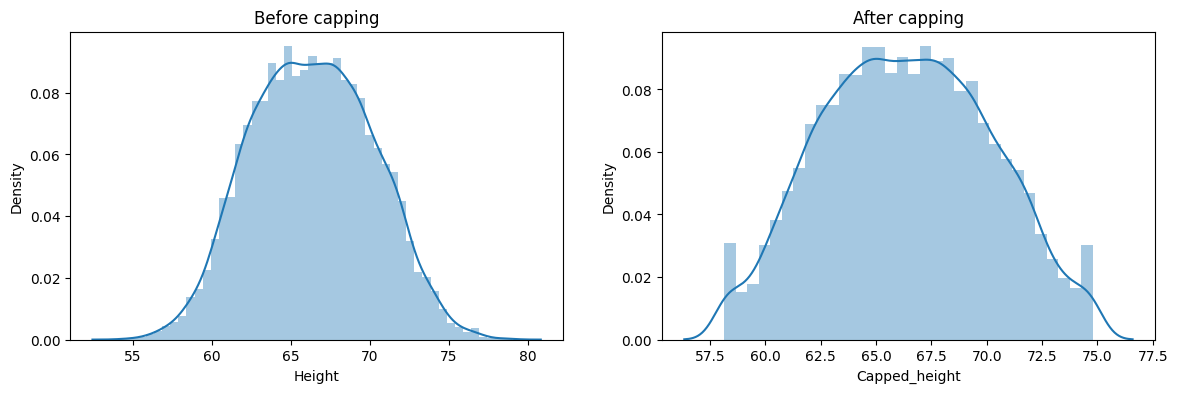

In [25]:
# distplot

plt.figure(figsize = (14, 4))

plt.subplot(121)
sns.distplot(df['Height'])
plt.title('Before capping')

plt.subplot(122)
sns.distplot(df2['Capped_height'])
plt.title('After capping')

Text(0.5, 1.0, 'After capping')

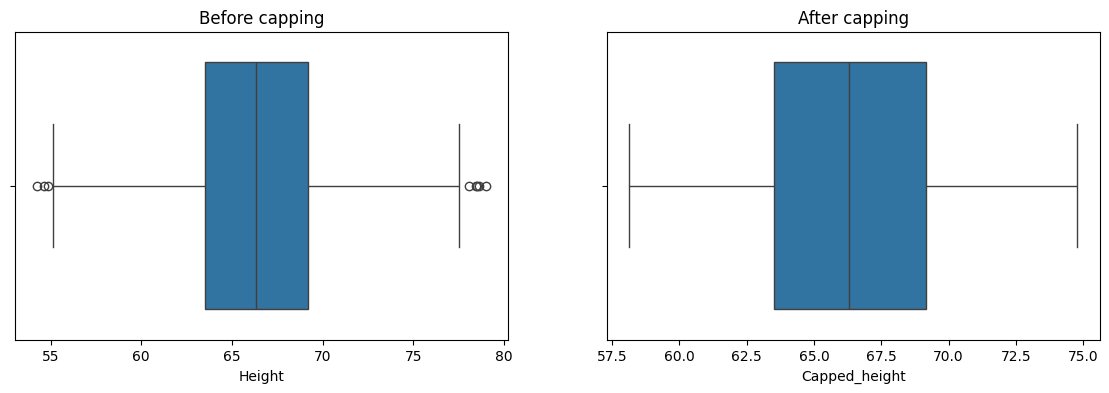

In [28]:
# Boxplot

plt.figure(figsize = (14, 4))

plt.subplot(121)
sns.boxplot(df['Height'], orient = 'h')
plt.title('Before capping')

plt.subplot(122)
sns.boxplot(df2['Capped_height'], orient = 'h')
plt.title('After capping')